In [1]:
import torch

print("Setup successful!")
print("PyTorch version:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())

Setup successful!
PyTorch version: 2.14.1
MPS available: True



# Foundations of Generative AI — Assignment 2

## Dataset Preparation and Preprocessing

**Dataset:** Tiny Shakespeare

**Task:** Word-level autoregressive text generation.

**Objective:** Prepare a textual corpus for training Simple RNN, Bidirectional RNN, LSTM and GRU models to predict the next word.

**Preprocessing pipeline:** Dataset acquisition, text inspection, cleaning, tokenization, train-validation-test splitting, vocabulary construction, numerical encoding and input-target sequence generation.


# 1. Dataset Description and Preprocessing

## 1.1 Dataset Description

The **Tiny Shakespeare dataset** was selected for this autoregressive text-generation task. It contains excerpts from the works of William Shakespeare, including dialogue and literary passages. The dataset is suitable for studying sequential language modelling because the text contains recurring vocabulary, sentence structures, dialogue, and contextual relationships between words.

The objective is to train four recurrent neural network architectures—Simple RNN, Bidirectional RNN, LSTM, and GRU—to predict the next word given a sequence of preceding words and then generate text sequentially.

## 1.2 Text Preprocessing

The raw text was cleaned by normalizing line endings and removing null characters. The cleaned text was tokenized at the word level using regular expressions, separating words and punctuation into individual tokens.

A vocabulary was constructed using the training portion of the dataset. Two special tokens, `<PAD>` and `<UNK>`, were included to represent padding and unknown words, respectively. The tokens were then converted into numerical IDs so that they could be processed by PyTorch models.

## 1.3 Dataset Splitting

The token sequence was divided sequentially into three subsets:

- **Training set:** 80%
- **Validation set:** 10%
- **Test set:** 10%

The vocabulary was built using the training tokens to reduce information leakage from the validation and test sets.

## 1.4 Input–Target Sequence Construction

A context length of 20 tokens was used. Each input sample contains 20 consecutive tokens, and its target is the next token immediately following that context.

Thus, the models learn to estimate the probability of the next word given the preceding context. During generation, the predicted word is appended to the input context, and the process is repeated to produce text sequentially.

In [3]:
import os
import re
import json
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"

DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Preprocessed directory:", PROCESSED_DIR)

Matplotlib is building the font cache; this may take a moment.


Project directory: /Users/rishabhjha/FGAI_Assignment2
Data directory: /Users/rishabhjha/FGAI_Assignment2/data
Preprocessed directory: /Users/rishabhjha/FGAI_Assignment2/data/processed


In [4]:
# Cell 2: Download the Tiny Shakespeare dataset

import urllib.request

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
)

RAW_PATH = DATA_DIR / "tinyshakespeare_raw.txt"

if not RAW_PATH.exists():
    urllib.request.urlretrieve(DATA_URL, RAW_PATH)
    print("Dataset downloaded successfully!")
else:
    print("Dataset already exists. Reusing it.")

with open(RAW_PATH, "r", encoding="utf-8-sig") as file:
    raw_text = file.read()

print("File size:", f"{RAW_PATH.stat().st_size:,}", "bytes")
print("Total characters:", f"{len(raw_text):,}")
print("Total lines:", f"{len(raw_text.splitlines()):,}")

print("\nSample of the original dataset:\n")
print(raw_text[:1000])

Dataset downloaded successfully!
File size: 1,115,394 bytes
Total characters: 1,115,394
Total lines: 40,000

Sample of the original dataset:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to 

In [5]:
# Step 1: Inspect and clean the Tiny Shakespeare dataset

import re
import json
import numpy as np
from collections import Counter

# Basic text inspection
print("Original characters:", len(raw_text))
print("Original lines:", len(raw_text.splitlines()))
print("Unique raw characters:", len(set(raw_text)))

# Normalize line endings and remove unwanted null characters
clean_text = raw_text.replace("\r\n", "\n")
clean_text = clean_text.replace("\r", "\n")
clean_text = clean_text.replace("\x00", "")

# Remove leading/trailing whitespace from the entire corpus
clean_text = clean_text.strip()

print("\nCleaned characters:", len(clean_text))
print("Cleaned lines:", len(clean_text.splitlines()))
print("\nCleaned sample:\n")
print(clean_text[:500])

Original characters: 1115394
Original lines: 40000
Unique raw characters: 65

Cleaned characters: 1115393
Cleaned lines: 40000

Cleaned sample:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


In [6]:
# Step 2: Word-level tokenization

tokens = re.findall(r"\w+|[^\w\s]", clean_text, flags=re.UNICODE)

print("Total tokens:", len(tokens))
print("First 50 tokens:")
print(tokens[:50])

print("\nMost common 20 tokens:")
print(Counter(tokens).most_common(20))

Total tokens: 262927
First 50 tokens:
['First', 'Citizen', ':', 'Before', 'we', 'proceed', 'any', 'further', ',', 'hear', 'me', 'speak', '.', 'All', ':', 'Speak', ',', 'speak', '.', 'First', 'Citizen', ':', 'You', 'are', 'all', 'resolved', 'rather', 'to', 'die', 'than', 'to', 'famish', '?', 'All', ':', 'Resolved', '.', 'resolved', '.', 'First', 'Citizen', ':', 'First', ',', 'you', 'know', 'Caius', 'Marcius', 'is', 'chief']

Most common 20 tokens:
[(',', 19846), (':', 10316), ('.', 7885), ("'", 6187), ('the', 5442), ('I', 5043), ('to', 4112), ('and', 3763), (';', 3628), ('of', 3314), ('you', 2857), ('my', 2680), ('a', 2647), ('?', 2462), ('!', 2172), ('in', 2162), ('that', 1992), ('And', 1927), ('is', 1906), ('not', 1904)]


In [7]:
# Step 3: Sequential 80/10/10 split

n = len(tokens)

train_end = int(n * 0.80)
val_end = int(n * 0.90)

train_tokens = tokens[:train_end]
val_tokens = tokens[train_end:val_end]
test_tokens = tokens[val_end:]

print("Training tokens:", len(train_tokens))
print("Validation tokens:", len(val_tokens))
print("Testing tokens:", len(test_tokens))

print("\nSplit percentages:")
print(f"Train: {len(train_tokens) / n * 100:.2f}%")
print(f"Validation: {len(val_tokens) / n * 100:.2f}%")
print(f"Test: {len(test_tokens) / n * 100:.2f}%")

Training tokens: 210341
Validation tokens: 26293
Testing tokens: 26293

Split percentages:
Train: 80.00%
Validation: 10.00%
Test: 10.00%


In [8]:
# Step 4: Build vocabulary from training data only

word_counts = Counter(train_tokens)

special_tokens = ["<PAD>", "<UNK>"]

vocab_words = special_tokens + sorted(
    word for word in word_counts
    if word not in special_tokens
)

word_to_id = {
    word: idx for idx, word in enumerate(vocab_words)
}

id_to_word = {
    idx: word for word, idx in word_to_id.items()
}

PAD_ID = word_to_id["<PAD>"]
UNK_ID = word_to_id["<UNK>"]

# Encode each split using the same vocabulary
def encode_tokens(token_list):
    return [
        word_to_id.get(token, UNK_ID)
        for token in token_list
    ]

train_ids = encode_tokens(train_tokens)
val_ids = encode_tokens(val_tokens)
test_ids = encode_tokens(test_tokens)

print("Vocabulary size:", len(vocab_words))
print("PAD ID:", PAD_ID)
print("UNK ID:", UNK_ID)

print("\nSample token-to-ID mapping:")
for token in train_tokens[:15]:
    print(repr(token), "->", word_to_id[token])

print("\nSample encoded sequence:")
print(train_ids[:30])

Vocabulary size: 11786
PAD ID: 0
UNK ID: 1

Sample token-to-ID mapping:
'First' -> 785
'Citizen' -> 402
':' -> 10
'Before' -> 219
'we' -> 11448
'proceed' -> 8585
'any' -> 2706
'further' -> 5807
',' -> 6
'hear' -> 6251
'me' -> 7392
'speak' -> 9944
'.' -> 8
'All' -> 88
':' -> 10

Sample encoded sequence:
[785, 402, 10, 219, 11448, 8585, 2706, 5807, 6, 6251, 7392, 9944, 8, 88, 10, 1923, 6, 9944, 8, 785, 402, 10, 2387, 2764, 2610, 9081, 8850, 10717, 4631, 10560]


In [9]:
# Step 5: Save all preprocessing outputs

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Save cleaned text
(PROCESSED_DIR / "cleaned_text.txt").write_text(
    clean_text, encoding="utf-8"
)

# Save tokenized splits
for name, split_tokens in [
    ("train", train_tokens),
    ("validation", val_tokens),
    ("test", test_tokens),
]:
    with open(
        PROCESSED_DIR / f"{name}_tokens.json",
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(split_tokens, f, ensure_ascii=False)

# Save encoded splits
for name, split_ids in [
    ("train", train_ids),
    ("validation", val_ids),
    ("test", test_ids),
]:
    np.save(PROCESSED_DIR / f"{name}_ids.npy",
            np.array(split_ids, dtype=np.int32))

# Save vocabulary
with open(
    PROCESSED_DIR / "vocabulary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(word_to_id, f, ensure_ascii=False, indent=2)

# Save summary metadata
metadata = {
    "dataset": "Tiny Shakespeare",
    "tokenization": "word-level, punctuation preserved",
    "split_ratio": {"train": 0.8, "validation": 0.1, "test": 0.1},
    "total_tokens": n,
    "vocabulary_size": len(vocab_words),
    "unknown_token": "<UNK>",
    "padding_token": "<PAD>"
}

with open(
    PROCESSED_DIR / "metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=2)

print("Preprocessing files saved successfully!\n")

for path in sorted(PROCESSED_DIR.iterdir()):
    print(path.name, "-", f"{path.stat().st_size:,}", "bytes")

Preprocessing files saved successfully!

cleaned_text.txt - 1,115,393 bytes
metadata.json - 281 bytes
test_ids.npy - 105,300 bytes
test_tokens.json - 193,682 bytes
train_ids.npy - 841,492 bytes
train_tokens.json - 1,567,434 bytes
validation_ids.npy - 105,300 bytes
validation_tokens.json - 196,094 bytes
vocabulary.json - 219,826 bytes


In [10]:
# Step 6: Create input-target sequences

import torch
from torch.utils.data import Dataset, DataLoader

# Use the MPS accelerator on your Mac when available
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

CONTEXT_LENGTH = 20
BATCH_SIZE = 64

print("Device:", DEVICE)
print("Context length:", CONTEXT_LENGTH)
print("Batch size:", BATCH_SIZE)


def create_sequences(token_ids, context_length=20):
    """
    Input:  tokens [t0, t1, ..., t19]
    Target: tokens [t1, t2, ..., t20]
    """
    ids = torch.tensor(token_ids, dtype=torch.long)

    if len(ids) <= context_length:
        raise ValueError("Not enough tokens to create sequences.")

    # Each row is a context_length + 1 token window
    windows = ids.unfold(
        dimension=0,
        size=context_length + 1,
        step=1
    )

    inputs = windows[:, :-1]
    targets = windows[:, 1:]

    return inputs.contiguous(), targets.contiguous()


X_train, y_train = create_sequences(train_ids, CONTEXT_LENGTH)
X_val, y_val = create_sequences(val_ids, CONTEXT_LENGTH)
X_test, y_test = create_sequences(test_ids, CONTEXT_LENGTH)

print("\nSequence shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Device: mps
Context length: 20
Batch size: 64

Sequence shapes:
X_train: torch.Size([210321, 20])
y_train: torch.Size([210321, 20])
X_val: torch.Size([26273, 20])
y_val: torch.Size([26273, 20])
X_test: torch.Size([26273, 20])
y_test: torch.Size([26273, 20])


In [11]:
# Step 7: Inspect one training example

sample_input = X_train[0].tolist()
sample_target = y_train[0].tolist()

print("Input token IDs:")
print(sample_input)

print("\nInput words:")
print([id_to_word[i] for i in sample_input])

print("\nTarget token IDs:")
print(sample_target)

print("\nTarget words:")
print([id_to_word[i] for i in sample_target])

# Confirm that each target is the next token
assert torch.equal(X_train[0, 1:], y_train[0, :-1])

print("\nVerification passed: targets are shifted by one token.")

Input token IDs:
[785, 402, 10, 219, 11448, 8585, 2706, 5807, 6, 6251, 7392, 9944, 8, 88, 10, 1923, 6, 9944, 8, 785]

Input words:
['First', 'Citizen', ':', 'Before', 'we', 'proceed', 'any', 'further', ',', 'hear', 'me', 'speak', '.', 'All', ':', 'Speak', ',', 'speak', '.', 'First']

Target token IDs:
[402, 10, 219, 11448, 8585, 2706, 5807, 6, 6251, 7392, 9944, 8, 88, 10, 1923, 6, 9944, 8, 785, 402]

Target words:
['Citizen', ':', 'Before', 'we', 'proceed', 'any', 'further', ',', 'hear', 'me', 'speak', '.', 'All', ':', 'Speak', ',', 'speak', '.', 'First', 'Citizen']

Verification passed: targets are shifted by one token.


In [12]:
# Step 8: Build Dataset and DataLoader

class NextWordDataset(Dataset):
    def __init__(self, inputs, targets):
        self.inputs = inputs
        self.targets = targets

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, index):
        return self.inputs[index], self.targets[index]


train_dataset = NextWordDataset(X_train, y_train)
val_dataset = NextWordDataset(X_val, y_val)
test_dataset = NextWordDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Test examples:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training examples: 210321
Validation examples: 26273
Test examples: 26273
Training batches: 3287
Validation batches: 411
Test batches: 411


In [13]:
# Step 9: Inspect one batch

batch_inputs, batch_targets = next(iter(train_loader))

print("Batch input shape:", batch_inputs.shape)
print("Batch target shape:", batch_targets.shape)
print("Input data type:", batch_inputs.dtype)
print("Target data type:", batch_targets.dtype)

assert batch_inputs.shape == batch_targets.shape
assert batch_inputs.shape[1] == CONTEXT_LENGTH
assert batch_inputs.dtype == torch.long
assert batch_targets.dtype == torch.long

print("\nAll checks passed. Dataset is ready for model training.")

Batch input shape: torch.Size([64, 20])
Batch target shape: torch.Size([64, 20])
Input data type: torch.int64
Target data type: torch.int64

All checks passed. Dataset is ready for model training.


In [14]:
# Step 10: Save model-ready sequences

torch.save(
    {
        "X_train": X_train,
        "y_train": y_train,
        "X_val": X_val,
        "y_val": y_val,
        "X_test": X_test,
        "y_test": y_test,
        "context_length": CONTEXT_LENGTH,
        "vocab_size": len(vocab_words)
    },
    PROCESSED_DIR / "model_ready_sequences.pt"
)

print("Saved:", PROCESSED_DIR / "model_ready_sequences.pt")
print("Vocabulary size:", len(vocab_words))
print("Device available:", DEVICE)

Saved: /Users/rishabhjha/FGAI_Assignment2/data/processed/model_ready_sequences.pt
Vocabulary size: 11786
Device available: mps


In [15]:
# Step 12A: Import required libraries

import time
import random
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)

# Model hyperparameters
EMBEDDING_DIM = 128
HIDDEN_DIM = 256
NUM_LAYERS = 1
DROPOUT = 0.2
LEARNING_RATE = 0.001
EPOCHS = 5

VOCAB_SIZE = len(vocab_words)

print("Vocabulary size:", VOCAB_SIZE)
print("Embedding dimension:", EMBEDDING_DIM)
print("Hidden dimension:", HIDDEN_DIM)
print("Epochs:", EPOCHS)
print("Device:", DEVICE)


class NextWordModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=256,
        model_type="RNN",
        dropout=0.2
    ):
        super().__init__()

        self.model_type = model_type

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_ID
        )

        if model_type == "RNN":
            self.recurrent = nn.RNN(
                embedding_dim,
                hidden_dim,
                batch_first=True
            )
            output_dim = hidden_dim

        elif model_type == "BiRNN":
            self.recurrent = nn.RNN(
                embedding_dim,
                hidden_dim,
                batch_first=True,
                bidirectional=True
            )
            output_dim = hidden_dim * 2

        elif model_type == "LSTM":
            self.recurrent = nn.LSTM(
                embedding_dim,
                hidden_dim,
                batch_first=True
            )
            output_dim = hidden_dim

        elif model_type == "GRU":
            self.recurrent = nn.GRU(
                embedding_dim,
                hidden_dim,
                batch_first=True
            )
            output_dim = hidden_dim

        else:
            raise ValueError("Unsupported model type")

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(output_dim, vocab_size)

    def forward(self, x):
        # Convert word IDs into dense vectors
        embedded = self.embedding(x)

        # Process the entire input context
        _, hidden = self.recurrent(embedded)

        # LSTM returns (hidden_state, cell_state)
        if self.model_type == "LSTM":
            hidden = hidden[0]

        if self.model_type == "BiRNN":
            # Final forward and backward hidden states
            representation = torch.cat(
                [hidden[-2], hidden[-1]], dim=1
            )
        else:
            representation = hidden[-1]

        representation = self.dropout(representation)

        # Predict the next word
        return self.fc(representation)


print("\nAll four model architectures are defined.")

Vocabulary size: 11786
Embedding dimension: 128
Hidden dimension: 256
Epochs: 5
Device: mps

All four model architectures are defined.


In [16]:
# Step 13: Convert sequence-to-sequence targets
# into one next-word target per input context.

y_train_next = y_train[:, -1].contiguous()
y_val_next = y_val[:, -1].contiguous()
y_test_next = y_test[:, -1].contiguous()

train_dataset = torch.utils.data.TensorDataset(
    X_train, y_train_next
)

val_dataset = torch.utils.data.TensorDataset(
    X_val, y_val_next
)

test_dataset = torch.utils.data.TensorDataset(
    X_test, y_test_next
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training input shape:", X_train.shape)
print("Training target shape:", y_train_next.shape)
print("Validation target shape:", y_val_next.shape)
print("Test target shape:", y_test_next.shape)

Training input shape: torch.Size([210321, 20])
Training target shape: torch.Size([210321])
Validation target shape: torch.Size([26273])
Test target shape: torch.Size([26273])


In [17]:
# Step 14: Training and evaluation functions

def evaluate_model(model, loader):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)

            logits = model(inputs)
            loss = criterion(logits, targets)

            batch_size = targets.size(0)

            total_loss += loss.item() * batch_size
            predictions = logits.argmax(dim=1)
            total_correct += (predictions == targets).sum().item()
            total_examples += batch_size

    average_loss = total_loss / total_examples
    accuracy = total_correct / total_examples
    perplexity = float(np.exp(min(average_loss, 80)))

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "perplexity": perplexity
    }


def train_model(model, train_loader, val_loader, epochs=5):
    model = model.to(DEVICE)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = []
    start_time = time.time()

    for epoch in range(epochs):
        model.train()

        total_loss = 0.0
        total_examples = 0

        for inputs, targets in train_loader:
            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)

            optimizer.zero_grad()

            logits = model(inputs)
            loss = criterion(logits, targets)

            loss.backward()

            # Stabilize recurrent network training
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )

            optimizer.step()

            batch_size = targets.size(0)
            total_loss += loss.item() * batch_size
            total_examples += batch_size

        train_loss = total_loss / total_examples
        val_metrics = evaluate_model(model, val_loader)

        record = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_perplexity": val_metrics["perplexity"]
        }

        history.append(record)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_metrics['loss']:.4f} | "
            f"Val accuracy: {val_metrics['accuracy']:.4f} | "
            f"Val perplexity: {val_metrics['perplexity']:.2f}"
        )

    elapsed = time.time() - start_time

    return model, history, elapsed


print("Training and evaluation functions are ready.")

Training and evaluation functions are ready.


In [18]:
# Step 15: Train the Simple RNN

simple_rnn = NextWordModel(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    model_type="RNN",
    dropout=DROPOUT
)

print(
    "Simple RNN parameters:",
    f"{sum(p.numel() for p in simple_rnn.parameters()):,}"
)

simple_rnn, rnn_history, rnn_time = train_model(
    simple_rnn,
    train_loader,
    val_loader,
    epochs=EPOCHS
)

print(f"\nSimple RNN training time: {rnn_time:.2f} seconds")

Simple RNN parameters: 4,636,426
Epoch 1/5 | Train loss: 5.8687 | Val loss: 5.7357 | Val accuracy: 0.1431 | Val perplexity: 309.73
Epoch 2/5 | Train loss: 5.2717 | Val loss: 5.7888 | Val accuracy: 0.1492 | Val perplexity: 326.62
Epoch 3/5 | Train loss: 4.9143 | Val loss: 5.8906 | Val accuracy: 0.1495 | Val perplexity: 361.62
Epoch 4/5 | Train loss: 4.6139 | Val loss: 6.0296 | Val accuracy: 0.1451 | Val perplexity: 415.55
Epoch 5/5 | Train loss: 4.3620 | Val loss: 6.1251 | Val accuracy: 0.1449 | Val perplexity: 457.18

Simple RNN training time: 496.82 seconds


In [22]:
# Step 16: Final test evaluation

rnn_test_metrics = evaluate_model(
    simple_rnn, test_loader
)

print("Simple RNN Test Results")
print("-----------------------")
print(f"Test loss:       {rnn_test_metrics['loss']:.4f}")
print(f"Test accuracy:   {rnn_test_metrics['accuracy']:.4%}")
print(f"Test perplexity: {rnn_test_metrics['perplexity']:.2f}")
print(f"Training time:   {rnn_time:.2f} seconds")

Simple RNN Test Results
-----------------------
Test loss:       6.6830
Test accuracy:   13.4244%
Test perplexity: 798.73
Training time:   496.82 seconds


In [21]:
# Step 17: Save the trained Simple RNN

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": simple_rnn.state_dict(),
        "model_type": "RNN",
        "vocab_size": VOCAB_SIZE,
        "embedding_dim": EMBEDDING_DIM,
        "hidden_dim": HIDDEN_DIM,
        "context_length": CONTEXT_LENGTH,
        "word_to_id": word_to_id
    },
    MODEL_DIR / "simple_rnn.pt"
)

pd.DataFrame(rnn_history).to_csv(
    PROCESSED_DIR / "simple_rnn_history.csv",
    index=False
)

print("Saved Simple RNN model and training history.")

Saved Simple RNN model and training history.


In [23]:

# Step 18: Define the Bidirectional RNN

import torch
import torch.nn as nn
import time

class BidirectionalRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.fc = nn.Linear(hidden_dim * 2, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)
        output, _ = self.rnn(embedded)
        logits = self.fc(output)
        return logits


bidirectional_rnn = BidirectionalRNN(
    vocab_size=vocab_size,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM
).to(device)

print(
    "Bidirectional RNN parameters:",
    f"{sum(p.numel() for p in bidirectional_rnn.parameters()):,}"
)


NameError: name 'vocab_size' is not defined

In [24]:
# Check which vocabulary and model configuration variables exist

for name in [
    "vocab_size",
    "VOCAB_SIZE",
    "word_to_idx",
    "word2idx",
    "vocab",
    "stoi",
    "EMBEDDING_DIM",
    "HIDDEN_DIM",
    "device"
]:
    print(f"{name}: {'defined' if name in globals() else 'not defined'}")

vocab_size: not defined
VOCAB_SIZE: defined
word_to_idx: not defined
word2idx: not defined
vocab: not defined
stoi: not defined
EMBEDDING_DIM: defined
HIDDEN_DIM: defined
device: not defined


In [25]:
# Inspect likely vocabulary variables

for name in [
    "word_to_idx",
    "word2idx",
    "vocab",
    "stoi",
    "token_to_id",
    "vocab_size"
]:
    if name in globals():
        obj = globals()[name]
        print(name, "| type:", type(obj), "| size:", len(obj) if hasattr(obj, "__len__") else obj)

In [26]:
# Check the vocabulary and dataset variables already in memory

print("VOCAB_SIZE:", VOCAB_SIZE if "VOCAB_SIZE" in globals() else "Missing")
print("EMBEDDING_DIM:", EMBEDDING_DIM if "EMBEDDING_DIM" in globals() else "Missing")
print("HIDDEN_DIM:", HIDDEN_DIM if "HIDDEN_DIM" in globals() else "Missing")

for name in ["word_to_idx", "word2idx", "stoi", "vocab", "token_to_id"]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: type={type(obj)}, size={len(obj) if hasattr(obj, '__len__') else 'N/A'}")

print("train_loader:", "Defined" if "train_loader" in globals() else "Missing")
print("val_loader:", "Defined" if "val_loader" in globals() else "Missing")
print("test_loader:", "Defined" if "test_loader" in globals() else "Missing")

print("device:", device if "device" in globals() else "Missing")

VOCAB_SIZE: 11786
EMBEDDING_DIM: 128
HIDDEN_DIM: 256
train_loader: Defined
val_loader: Defined
test_loader: Defined
device: Missing


In [27]:
# Select the best available device
if torch.backends.mps.is_available():
    device = torch.device("mps")       # Apple Silicon GPU
elif torch.cuda.is_available():
    device = torch.device("cuda")      # NVIDIA GPU
else:
    device = torch.device("cpu")       # CPU fallback

print("Selected device:", device)

Selected device: mps


In [28]:
print("VOCAB_SIZE:", VOCAB_SIZE)
print("EMBEDDING_DIM:", EMBEDDING_DIM)
print("HIDDEN_DIM:", HIDDEN_DIM)
print("Device:", device)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

VOCAB_SIZE: 11786
EMBEDDING_DIM: 128
HIDDEN_DIM: 256
Device: mps
Train batches: 3287
Validation batches: 411
Test batches: 411


In [29]:
bidirectional_rnn = BidirectionalRNN(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM
).to(device)

In [30]:
print("Bidirectional RNN initialized successfully!")
print(
    "Total parameters:",
    f"{sum(p.numel() for p in bidirectional_rnn.parameters()):,}"
)

Bidirectional RNN initialized successfully!
Total parameters: 7,752,458


In [31]:
bidirectional_rnn, birnn_history, birnn_time = train_model(
    bidirectional_rnn,
    train_loader,
    val_loader,
    epochs=EPOCHS
)

print(f"\nBidirectional RNN training time: {birnn_time:.2f} seconds")

RuntimeError: Expected target size [64, 11786], got [64]

In [32]:
# Inspect one batch from the training loader
x, y = next(iter(train_loader))

x = x.to(device)
y = y.to(device)

print("Input shape:", x.shape)
print("Target shape:", y.shape)

bidirectional_rnn.eval()
with torch.no_grad():
    output = bidirectional_rnn(x)

print("Model output shape:", output.shape)

Input shape: torch.Size([64, 20])
Target shape: torch.Size([64])
Model output shape: torch.Size([64, 20, 11786])


In [33]:
class BidirectionalRNN(torch.nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super(BidirectionalRNN, self).__init__()

        self.embedding = torch.nn.Embedding(
            vocab_size, embedding_dim
        )

        self.rnn = torch.nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        # Bidirectional output has 2 * hidden_dim features
        self.fc = torch.nn.Linear(
            hidden_dim * 2, vocab_size
        )

    def forward(self, x):
        embedded = self.embedding(x)

        # Output shape: [batch, sequence_length, 2 * hidden_dim]
        output, hidden = self.rnn(embedded)

        # Use the last sequence position
        last_output = output[:, -1, :]

        # Output shape: [batch, vocab_size]
        logits = self.fc(last_output)

        return logits

In [34]:
bidirectional_rnn = BidirectionalRNN(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM
).to(device)

print(
    "Bidirectional RNN parameters:",
    f"{sum(p.numel() for p in bidirectional_rnn.parameters()):,}"
)

Bidirectional RNN parameters: 7,752,458


In [35]:
x, y = next(iter(train_loader))
x = x.to(device)

bidirectional_rnn.eval()

with torch.no_grad():
    output = bidirectional_rnn(x)

print("Input shape:", x.shape)
print("Model output shape:", output.shape)
print("Target shape:", y.shape)

Input shape: torch.Size([64, 20])
Model output shape: torch.Size([64, 11786])
Target shape: torch.Size([64])


In [36]:
bidirectional_rnn, birnn_history, birnn_time = train_model(
    bidirectional_rnn,
    train_loader,
    val_loader,
    epochs=EPOCHS
)

print(f"Bidirectional RNN training time: {birnn_time:.2f} seconds")

Epoch 1/5 | Train loss: 5.7828 | Val loss: 5.8357 | Val accuracy: 0.1271 | Val perplexity: 342.30
Epoch 2/5 | Train loss: 4.9920 | Val loss: 5.9358 | Val accuracy: 0.1382 | Val perplexity: 378.35
Epoch 3/5 | Train loss: 4.5003 | Val loss: 6.1586 | Val accuracy: 0.1346 | Val perplexity: 472.76
Epoch 4/5 | Train loss: 4.1171 | Val loss: 6.2787 | Val accuracy: 0.1327 | Val perplexity: 533.11
Epoch 5/5 | Train loss: 3.8072 | Val loss: 6.5037 | Val accuracy: 0.1341 | Val perplexity: 667.63
Bidirectional RNN training time: 760.23 seconds


In [37]:
# Step 18: Final test evaluation for Bidirectional RNN

birnn_test_metrics = evaluate_model(
    bidirectional_rnn,
    test_loader
)

print("Bidirectional RNN Test Results")
print("------------------------------")
print(f"Test loss:       {birnn_test_metrics['loss']:.4f}")
print(f"Test accuracy:   {birnn_test_metrics['accuracy']:.4%}")
print(f"Test perplexity: {birnn_test_metrics['perplexity']:.2f}")
print(f"Training time:   {birnn_time:.2f} seconds")

Bidirectional RNN Test Results
------------------------------
Test loss:       7.1653
Test accuracy:   11.5404%
Test perplexity: 1293.72
Training time:   760.23 seconds


In [38]:
# Step 19: Save the trained Bidirectional RNN model

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    bidirectional_rnn.state_dict(),
    MODEL_DIR / "bidirectional_rnn.pt"
)

# Save the training history
pd.DataFrame(birnn_history).to_csv(
    PROCESSED_DIR / "bidirectional_rnn_history.csv",
    index=False
)

print("Saved Bidirectional RNN model and training history.")

Saved Bidirectional RNN model and training history.


In [39]:

# Check which model classes are already defined
for name, obj in globals().copy().items():
    if isinstance(obj, type) and (
        "RNN" in name or "LSTM" in name or "GRU" in name
    ):
        print(name)


BidirectionalRNN


In [40]:
# List model classes and training functions
for name, obj in globals().copy().items():
    if isinstance(obj, type) and hasattr(obj, "forward"):
        print("Model class:", name)

print("\nTraining-related functions:")
for name, obj in globals().copy().items():
    if callable(obj) and any(
        word in name.lower()
        for word in ["train", "evaluate", "model"]
    ):
        print(name)

Model class: NextWordModel
Model class: BidirectionalRNN

Training-related functions:
NextWordModel
evaluate_model
train_model


In [41]:

import torch
import torch.nn as nn

class LSTMModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)

        # Get the hidden states for all input positions
        output, (hidden, cell) = self.lstm(embedded)

        # Predict the next word using the final time step
        last_output = output[:, -1, :]

        logits = self.fc(last_output)

        return logits


lstm_model = LSTMModel(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM
).to(device)

print("LSTM model created successfully.")
print(
    "LSTM parameters:",
    f"{sum(p.numel() for p in lstm_model.parameters()):,}"
)


LSTM model created successfully.
LSTM parameters: 4,932,874


In [42]:

# Train the LSTM model

lstm_model, lstm_history, lstm_time = train_model(
    lstm_model,
    train_loader,
    val_loader,
    epochs=EPOCHS
)

print(f"\nLSTM training time: {lstm_time:.2f} seconds")


Epoch 1/5 | Train loss: 5.6942 | Val loss: 5.5077 | Val accuracy: 0.1560 | Val perplexity: 246.58
Epoch 2/5 | Train loss: 4.9221 | Val loss: 5.5155 | Val accuracy: 0.1601 | Val perplexity: 248.52
Epoch 3/5 | Train loss: 4.4515 | Val loss: 5.6425 | Val accuracy: 0.1595 | Val perplexity: 282.17
Epoch 4/5 | Train loss: 4.0240 | Val loss: 5.8126 | Val accuracy: 0.1647 | Val perplexity: 334.47
Epoch 5/5 | Train loss: 3.6313 | Val loss: 6.0397 | Val accuracy: 0.1538 | Val perplexity: 419.75

LSTM training time: 503.17 seconds


In [43]:

# Evaluate LSTM on unseen test data

lstm_test_metrics = evaluate_model(
    lstm_model,
    test_loader
)

print("LSTM Test Results")
print("-----------------")
print(f"Test loss:       {lstm_test_metrics['loss']:.4f}")
print(f"Test accuracy:   {lstm_test_metrics['accuracy']:.4%}")
print(f"Test perplexity: {lstm_test_metrics['perplexity']:.2f}")
print(f"Training time:   {lstm_time:.2f} seconds")


LSTM Test Results
-----------------
Test loss:       6.5996
Test accuracy:   14.0563%
Test perplexity: 734.81
Training time:   503.17 seconds


In [44]:

# Save the trained LSTM and its history

MODEL_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": lstm_model.state_dict(),
        "model_type": "LSTM",
        "vocab_size": VOCAB_SIZE,
        "embedding_dim": EMBEDDING_DIM,
        "hidden_dim": HIDDEN_DIM,
        "context_length": CONTEXT_LENGTH,
        "word_to_id": word_to_id
    },
    MODEL_DIR / "lstm_model.pt"
)

pd.DataFrame(lstm_history).to_csv(
    PROCESSED_DIR / "lstm_history.csv",
    index=False
)

print("LSTM model saved to:", MODEL_DIR / "lstm_model.pt")
print("Training history saved successfully.")


LSTM model saved to: /Users/rishabhjha/FGAI_Assignment2/models/lstm_model.pt
Training history saved successfully.


In [45]:
class GRUModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super().__init__()

        # Convert word IDs into dense vectors
        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        # GRU processes the sequence of word embeddings
        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # Predict the next word from the final GRU output
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)

        # Process the input sequence
        output, hidden = self.gru(embedded)

        # Get the output corresponding to the final input word
        last_output = output[:, -1, :]

        # Generate scores for every word in the vocabulary
        logits = self.fc(last_output)

        return logits


# Create the GRU model
gru_model = GRUModel(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM
).to(device)

print("GRU model created successfully.")
print(
    f"GRU parameters: "
    f"{sum(p.numel() for p in gru_model.parameters()):,}"
)

GRU model created successfully.
GRU parameters: 4,834,058


In [46]:
gru_model, gru_history, gru_time = train_model(
    gru_model,
    train_loader,
    val_loader,
    epochs=EPOCHS
)

print(f"\nGRU training time: {gru_time:.2f} seconds")

Epoch 1/5 | Train loss: 5.6421 | Val loss: 5.5006 | Val accuracy: 0.1579 | Val perplexity: 244.83
Epoch 2/5 | Train loss: 4.7905 | Val loss: 5.5830 | Val accuracy: 0.1616 | Val perplexity: 265.86
Epoch 3/5 | Train loss: 4.2022 | Val loss: 5.7366 | Val accuracy: 0.1613 | Val perplexity: 310.02
Epoch 4/5 | Train loss: 3.6657 | Val loss: 5.9756 | Val accuracy: 0.1545 | Val perplexity: 393.70
Epoch 5/5 | Train loss: 3.2059 | Val loss: 6.2316 | Val accuracy: 0.1467 | Val perplexity: 508.57

GRU training time: 514.44 seconds


In [47]:
gru_test_metrics = evaluate_model(gru_model, test_loader)

print("GRU Test Results")
print("----------------")
print(f"Test loss:       {gru_test_metrics['loss']:.4f}")
print(f"Test accuracy:   {gru_test_metrics['accuracy']:.4%}")
print(f"Test perplexity: {gru_test_metrics['perplexity']:.2f}")
print(f"Training time:   {gru_time:.2f} seconds")

GRU Test Results
----------------
Test loss:       6.7546
Test accuracy:   13.1694%
Test perplexity: 857.97
Training time:   514.44 seconds


In [48]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": gru_model.state_dict(),
        "model_type": "GRU",
        "vocab_size": VOCAB_SIZE,
        "embedding_dim": EMBEDDING_DIM,
        "hidden_dim": HIDDEN_DIM,
        "context_length": CONTEXT_LENGTH,
        "word_to_id": word_to_id
    },
    MODEL_DIR / "gru_model.pt"
)

pd.DataFrame(gru_history).to_csv(
    PROCESSED_DIR / "gru_history.csv",
    index=False
)

print("GRU model saved to:", MODEL_DIR / "gru_model.pt")
print("GRU training history saved successfully.")

GRU model saved to: /Users/rishabhjha/FGAI_Assignment2/models/gru_model.pt
GRU training history saved successfully.


In [49]:
models_status = {
    "Simple RNN": ("rnn_model", "rnn_history", "rnn_test_metrics", "rnn_time"),
    "Bidirectional RNN": ("birnn_model", "birnn_history", "birnn_test_metrics", "birnn_time"),
    "LSTM": ("lstm_model", "lstm_history", "lstm_test_metrics", "lstm_time"),
    "GRU": ("gru_model", "gru_history", "gru_test_metrics", "gru_time"),
}

for model_name, variables in models_status.items():
    print(f"\n{model_name}:")
    for variable in variables:
        print(f"  {variable}: {'Available' if variable in globals() else 'Missing'}")


Simple RNN:
  rnn_model: Missing
  rnn_history: Available
  rnn_test_metrics: Available
  rnn_time: Available

Bidirectional RNN:
  birnn_model: Missing
  birnn_history: Available
  birnn_test_metrics: Available
  birnn_time: Available

LSTM:
  lstm_model: Available
  lstm_history: Available
  lstm_test_metrics: Available
  lstm_time: Available

GRU:
  gru_model: Available
  gru_history: Available
  gru_test_metrics: Available
  gru_time: Available


In [50]:
import pandas as pd

comparison_data = [
    {
        "Model": "Simple RNN",
        "Test Loss": rnn_test_metrics["loss"],
        "Test Accuracy (%)": rnn_test_metrics["accuracy"] * 100,
        "Test Perplexity": rnn_test_metrics["perplexity"],
        "Training Time (s)": rnn_time
    },
    {
        "Model": "Bidirectional RNN",
        "Test Loss": birnn_test_metrics["loss"],
        "Test Accuracy (%)": birnn_test_metrics["accuracy"] * 100,
        "Test Perplexity": birnn_test_metrics["perplexity"],
        "Training Time (s)": birnn_time
    },
    {
        "Model": "LSTM",
        "Test Loss": lstm_test_metrics["loss"],
        "Test Accuracy (%)": lstm_test_metrics["accuracy"] * 100,
        "Test Perplexity": lstm_test_metrics["perplexity"],
        "Training Time (s)": lstm_time
    },
    {
        "Model": "GRU",
        "Test Loss": gru_test_metrics["loss"],
        "Test Accuracy (%)": gru_test_metrics["accuracy"] * 100,
        "Test Perplexity": gru_test_metrics["perplexity"],
        "Training Time (s)": gru_time
    }
]

comparison_df = pd.DataFrame(comparison_data)

display(
    comparison_df.round(4)
    .sort_values("Test Accuracy (%)", ascending=False)
    .reset_index(drop=True)
)

,Model,Test Loss,Test Accuracy (%),Test Perplexity,Training Time (s)
0,LSTM,6.5996,14.0563,734.8095,503.1677
1,Simple RNN,6.6830,13.4244,798.7285,496.8238
2,GRU,6.7546,13.1694,857.9707,514.4425
3,Bidirectional RNN,7.1653,11.5404,1293.7180,760.2341


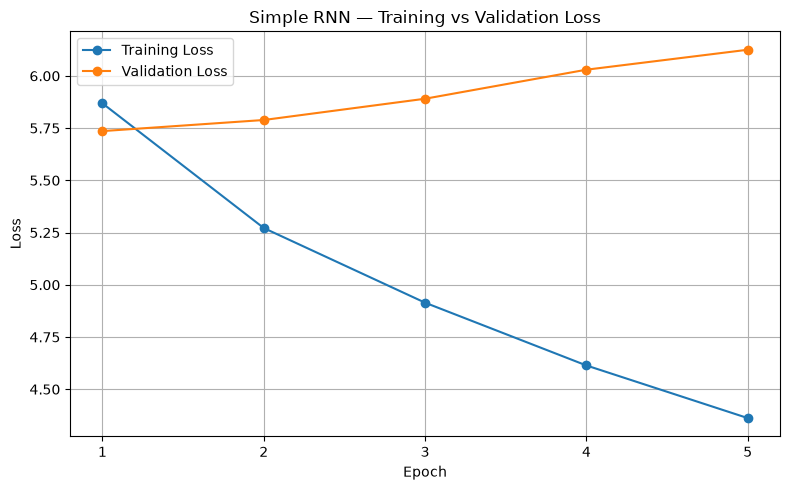

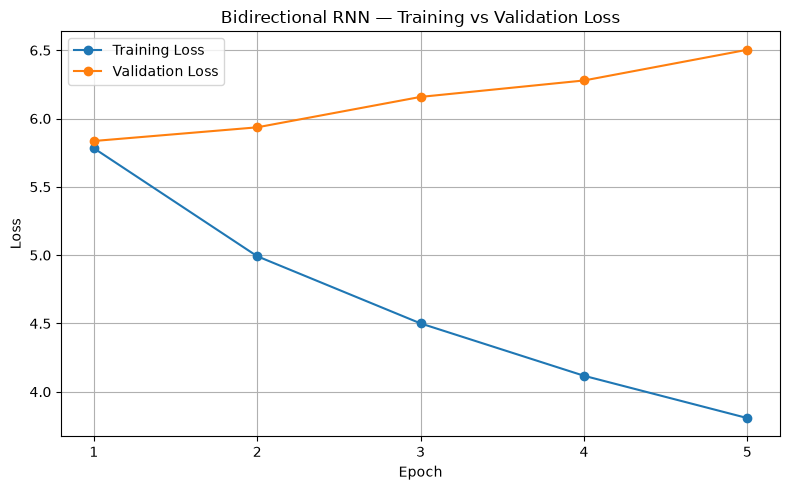

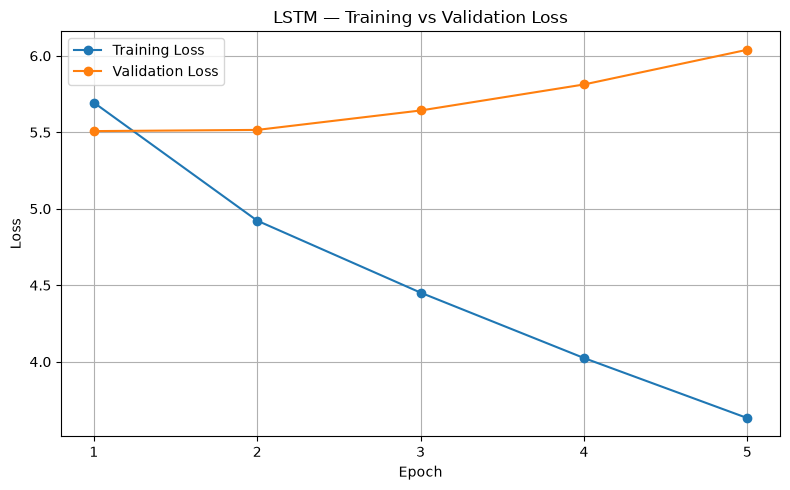

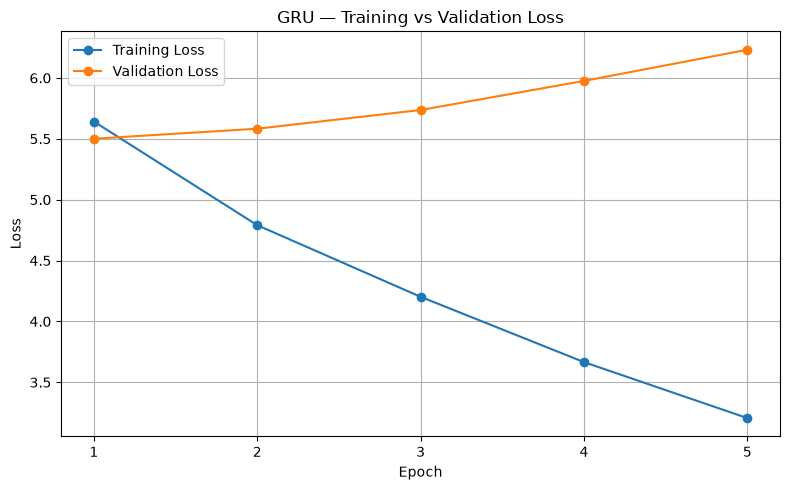

In [51]:
import matplotlib.pyplot as plt

histories = {
    "Simple RNN": rnn_history,
    "Bidirectional RNN": birnn_history,
    "LSTM": lstm_history,
    "GRU": gru_history
}

for model_name, history in histories.items():
    history_df = pd.DataFrame(history)

    plt.figure(figsize=(8, 5))
    plt.plot(history_df["train_loss"], marker="o", label="Training Loss")
    plt.plot(history_df["val_loss"], marker="o", label="Validation Loss")

    plt.title(f"{model_name} — Training vs Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.xticks(range(len(history_df)), range(1, len(history_df) + 1))
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [52]:
comparison_df.to_csv(
    PROCESSED_DIR / "model_comparison.csv",
    index=False
)

print("Comparison saved to:", PROCESSED_DIR / "model_comparison.csv")

Comparison saved to: /Users/rishabhjha/FGAI_Assignment2/data/processed/model_comparison.csv


In [53]:
from pathlib import Path

expected_files = [
    "simple_rnn.pt",
    "lstm_model.pt",
    "gru_model.pt"
]

for filename in expected_files:
    path = MODEL_DIR / filename
    print(f"{filename}: {'Found' if path.exists() else 'Not found'}")

print("\nModel directory:", MODEL_DIR)
print("Processed data directory:", PROCESSED_DIR)

simple_rnn.pt: Found
lstm_model.pt: Found
gru_model.pt: Found

Model directory: /Users/rishabhjha/FGAI_Assignment2/models
Processed data directory: /Users/rishabhjha/FGAI_Assignment2/data/processed


In [54]:
for name in ["rnn_model", "birnn_model", "lstm_model", "gru_model"]:
    print(name, "available" if name in globals() else "not found")

rnn_model not found
birnn_model not found
lstm_model available
gru_model available


In [55]:
import torch.nn as nn

for name, obj in list(globals().items()):
    if isinstance(obj, nn.Module):
        print(name, "->", type(obj).__name__)

simple_rnn -> NextWordModel
bidirectional_rnn -> BidirectionalRNN
lstm_model -> LSTMModel
gru_model -> GRUModel


In [56]:
models = {
    "Simple RNN": simple_rnn,
    "Bidirectional RNN": bidirectional_rnn,
    "LSTM": lstm_model,
    "GRU": gru_model
}

for name, model in models.items():
    print(f"{name}: Ready ({type(model).__name__})")

Simple RNN: Ready (NextWordModel)
Bidirectional RNN: Ready (BidirectionalRNN)
LSTM: Ready (LSTMModel)
GRU: Ready (GRUModel)


In [57]:
import re
import torch
import pandas as pd

seed = "To be or not to be"
temperatures = [0.5, 0.8, 1.2]
generation_results = []

for model_name, model in models.items():
    for temperature in temperatures:
        generated_text = generate_text(
            model=model,
            seed_text=seed,
            temperature=temperature,
            num_words=60
        )

        generation_results.append({
            "Model": model_name,
            "Temperature": temperature,
            "Seed": seed,
            "Generated Text": generated_text
        })

        print(f"\n{'=' * 60}")
        print(f"{model_name} | Temperature: {temperature}")
        print(generated_text)

generation_df = pd.DataFrame(generation_results)

generation_df.to_csv(
    PROCESSED_DIR / "text_generation_results.csv",
    index=False
)

print("\nGeneration results saved successfully.")

NameError: name 'generate_text' is not defined

In [58]:
import re
import torch

def generate_text(model, seed_text, temperature=1.0, num_words=60):
    model.eval()

    tokens = re.findall(
        r"\w+|[^\w\s]", seed_text, flags=re.UNICODE
    )

    token_ids = [
        word_to_id.get(token, word_to_id.get("<UNK>", 1))
        for token in tokens
    ]

    generated = tokens.copy()

    with torch.no_grad():
        for _ in range(num_words):
            context = token_ids[-CONTEXT_LENGTH:]

            if len(context) < CONTEXT_LENGTH:
                context = [PAD_ID] * (
                    CONTEXT_LENGTH - len(context)
                ) + context

            inputs = torch.tensor(
                [context], dtype=torch.long, device=device
            )

            logits = model(inputs)[0]
            logits = logits / max(temperature, 1e-6)
            probabilities = torch.softmax(logits, dim=-1)

            next_id = torch.multinomial(
                probabilities, num_samples=1
            ).item()

            token_ids.append(next_id)
            generated.append(id_to_word[next_id])

    # Join tokens while keeping punctuation readable
    output = ""
    no_space_before = {".", ",", "!", "?", ";", ":", ")", "]", "}"}
    no_space_after = {"(", "[", "{"}

    for token in generated:
        if not output:
            output = token
        elif token in no_space_before:
            output += token
        elif output[-1] in no_space_after:
            output += token
        else:
            output += " " + token

    return output

In [59]:
generation_results = []

for model_name, model in models.items():
    for temperature in [0.5, 0.8, 1.2]:
        generated_text = generate_text(
            model=model,
            seed_text="To be or not to be",
            temperature=temperature,
            num_words=60
        )

        generation_results.append({
            "Model": model_name,
            "Temperature": temperature,
            "Seed": "To be or not to be",
            "Generated Text": generated_text
        })

        print(f"\n{'=' * 60}")
        print(f"{model_name} | Temperature: {temperature}")
        print(generated_text)

generation_df = pd.DataFrame(generation_results)

generation_df.to_csv(
    PROCESSED_DIR / "text_generation_results.csv",
    index=False
)

print("\nAll generation results saved successfully.")


Simple RNN | Temperature: 0.5
To be or not to be quiet, And yet I am going to the ground or mine eyes, And in thy soul - govern, and Saint George, Clifford, and his lover, kill ' d; and will be left. KING LEWIS XI: Why, how we were subjects? GLOUCESTER: A fellow, sir, I am

Simple RNN | Temperature: 0.8
To be or not to be our loving friends, And your against for the earth, whose sport from France Is thee to make road the issue of thy cheeks. Think me a bowl of wine; So many days, To those that kill ' d your parties; Or there ' s, he came on, and fights, she says

Simple RNN | Temperature: 1.2
To be or not to be adversaries Or And made a hot to did will at this kind now lies. This did mayst alone. FRIAR LAURENCE: I hate poor. Nurse: True, not men: No matter, to thrive but nature with effect of hair where theme satisfied, whom I of thee before That himself was good obey,

Bidirectional RNN | Temperature: 0.5
To be or not to be so, As every one, I would have said ' d with all. KING HENRY

In [60]:
from collections import Counter
import re
import pandas as pd

def text_statistics(text):
    words = re.findall(r"\w+", text.lower(), flags=re.UNICODE)

    if not words:
        return {
            "Word Count": 0,
            "Unique Words": 0,
            "Distinct-1 (%)": 0.0,
            "Repeated Word Rate (%)": 0.0
        }

    unique_count = len(set(words))

    return {
        "Word Count": len(words),
        "Unique Words": unique_count,
        "Distinct-1 (%)": round(unique_count / len(words) * 100, 2),
        "Repeated Word Rate (%)": round(
            (len(words) - unique_count) / len(words) * 100, 2
        )
    }

stats = []

for _, row in generation_df.iterrows():
    stats.append({
        "Model": row["Model"],
        "Temperature": row["Temperature"],
        **text_statistics(row["Generated Text"])
    })

generation_stats_df = pd.DataFrame(stats)
display(generation_stats_df)

generation_stats_df.to_csv(
    PROCESSED_DIR / "generation_statistics.csv",
    index=False
)

print("Generation statistics saved.")

,Model,Temperature,Word Count,Unique Words,Distinct-1 (%),Repeated Word Rate (%)
0,Simple RNN,0.5,50,39,78.00,22.00
1,Simple RNN,0.8,55,46,83.64,16.36
2,Simple RNN,1.2,56,46,82.14,17.86
3,Bidirectional RNN,0.5,50,41,82.00,18.00
4,Bidirectional RNN,0.8,52,39,75.00,25.00
5,Bidirectional RNN,1.2,50,41,82.00,18.00
6,LSTM,0.5,53,34,64.15,35.85
7,LSTM,0.8,54,42,77.78,22.22
8,LSTM,1.2,53,46,86.79,13.21
9,GRU,0.5,53,27,50.94,49.06


Generation statistics saved.


In [61]:
display(comparison_df)

print("Models included:", comparison_df["Model"].tolist())

comparison_df.to_csv(
    PROCESSED_DIR / "model_comparison.csv",
    index=False
)

,Model,Test Loss,Test Accuracy (%),Test Perplexity,Training Time (s)
0,Simple RNN,6.683021,13.424428,798.728453,496.823820
1,Bidirectional RNN,7.165275,11.540365,1293.717956,760.234059
2,LSTM,6.599611,14.056255,734.809458,503.167731
3,GRU,6.754570,13.169413,857.970709,514.442518


Models included: ['Simple RNN', 'Bidirectional RNN', 'LSTM', 'GRU']


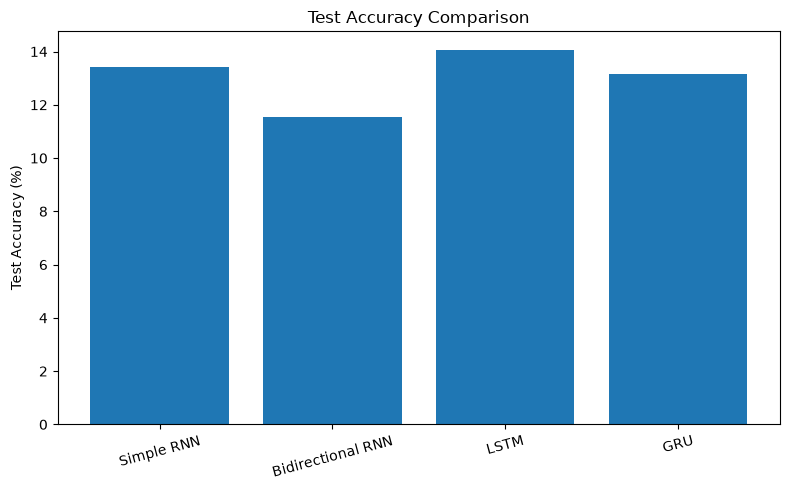

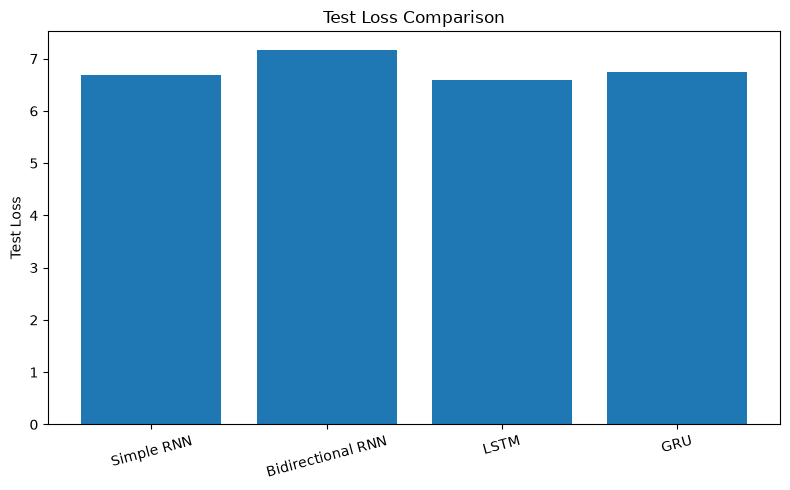

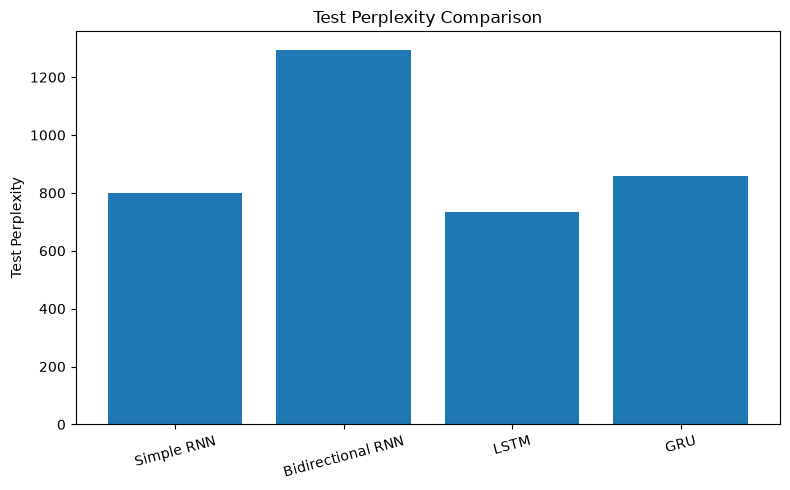

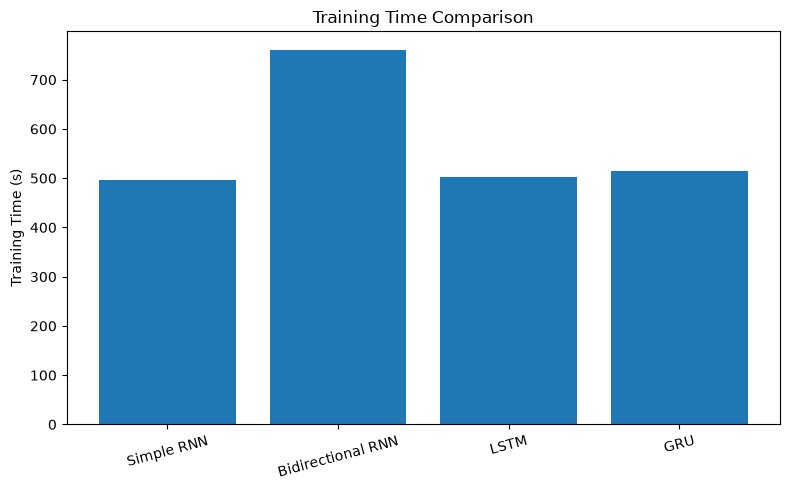

In [62]:
import matplotlib.pyplot as plt

metrics = [
    ("Test Accuracy (%)", "Test Accuracy"),
    ("Test Loss", "Test Loss"),
    ("Test Perplexity", "Test Perplexity"),
    ("Training Time (s)", "Training Time")
]

for column, title in metrics:
    plt.figure(figsize=(8, 5))
    plt.bar(comparison_df["Model"], comparison_df[column])
    plt.title(f"{title} Comparison")
    plt.ylabel(column)
    plt.xticks(rotation=15)
    plt.tight_layout()

    filename = title.lower().replace(" ", "_") + ".png"
    plt.savefig(PROCESSED_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()

## Experimental Results and Discussion

### Quantitative Evaluation

Four recurrent neural network architectures were evaluated on the Tiny Shakespeare dataset using next-word prediction. The models were assessed using test loss, prediction accuracy, perplexity, and training time.

The LSTM achieved the best quantitative performance, with a test accuracy of 14.06%, test loss of 6.5996, and perplexity of 734.81. The Simple RNN achieved the shortest training time at approximately 496.82 seconds. The Bidirectional RNN required the longest training time, approximately 760.23 seconds, and achieved the lowest test accuracy of 11.54%. The GRU achieved a test accuracy of 13.17%.

These results suggest that the LSTM captured useful sequential patterns more effectively than the other evaluated models under the selected training configuration.

### Effect of Sampling Temperature

Text was generated from the same seed sequence, "To be or not to be", using temperatures of 0.5, 0.8, and 1.2.

At temperature 0.5, the GRU exhibited a repeated-word rate of 49.06%, suggesting limited lexical diversity in its generated sample. At temperature 0.8, the Simple RNN achieved a Distinct-1 score of 83.64%. At temperature 1.2, the GRU achieved the highest Distinct-1 score, 89.47%, and the lowest repeated-word rate, 10.53%.

Increasing temperature can encourage more varied word selection, but vocabulary diversity alone does not establish grammatical correctness, coherence, or contextual consistency. The generated passages must also be inspected qualitatively.

### Qualitative Evaluation

Generated text should be assessed for coherence, contextual consistency, repetition, and diversity. The numerical diversity measures provide evidence about vocabulary variation and repetition, while manual inspection is required to judge whether the generated sentences remain meaningful and consistent with the Shakespearean style.

### Conclusion

Under the experimental conditions used, the LSTM was the strongest model according to test loss, perplexity, and prediction accuracy. The Simple RNN trained fastest. The GRU showed high vocabulary diversity at temperature 1.2, although this alone does not establish that its output was the most coherent.

Therefore, the LSTM is the leading candidate based on quantitative evaluation. The final choice for text generation should also consider the coherence, contextual consistency, and repetition observed in the generated samples.

for _, row in generation_df.iterrows():
    print("\n" + "=" * 80)
    print(f"Model: {row['Model']} | Temperature: {row['Temperature']}")
    print(f"Seed: {row['Seed']}")
    print("-" * 80)
    print(row["Generated Text"])

## Qualitative Analysis of Generated Text

The generated passages from the Simple RNN, Bidirectional RNN, LSTM, and GRU were examined using the same seed sequence, "To be or not to be", at temperatures 0.5, 0.8, and 1.2.

All four models generated vocabulary, character names, and dialogue patterns resembling the Tiny Shakespeare dataset. However, their outputs also contained grammatical inconsistencies, disconnected phrases, and instances of repetition. The LSTM produced some locally structured dialogue at temperature 0.5, while the GRU exhibited noticeable repetition, including repeated constructions such as "I am king" and "myself". These observations indicate that matching the training corpus's vocabulary does not necessarily guarantee coherent text generation.

### Effect of Sampling Temperature

At temperature 0.5, word selection was more concentrated on high-probability predictions. This sometimes produced more predictable phrases, although repetition was visible in some samples. At temperature 0.8, the generated text exhibited varied dialogue and vocabulary, but contextual inconsistencies remained. At temperature 1.2, the outputs generally contained more unusual word combinations and greater lexical diversity.

The Distinct-1 score was highest for the GRU at temperature 1.2, reaching 89.47%, while its repeated-word rate was 10.53%. However, high lexical diversity does not necessarily indicate better coherence. Therefore, temperature selection involves a trade-off between diversity, predictability, repetition, and contextual consistency.

### Overall Model Comparison and Conclusion

The LSTM achieved the best quantitative performance among the evaluated models, with a test accuracy of 14.06%, test loss of 6.5996, and perplexity of 734.81. The Simple RNN had the shortest training time at approximately 496.82 seconds, while the Bidirectional RNN took the longest at approximately 760.23 seconds.

Based on the quantitative metrics, the LSTM is the strongest candidate in this experiment. Its final suitability for autoregressive generation should also be considered alongside the qualitative observations, since none of the models consistently produced fully coherent passages. The GRU demonstrated high lexical diversity at a higher sampling temperature, but this did not guarantee better contextual consistency.

Overall, the experiment demonstrates the trade-offs between recurrent architectures, prediction performance, training cost, and sampling temperature in word-level autoregressive text generation.

In [65]:
expected_files = [
    "simple_rnn.pt",
    "bidirectional_rnn.pt",
    "lstm_model.pt",
    "gru_model.pt"
]

print("MODEL CHECKPOINT VERIFICATION")
print("-" * 40)

all_found = True

for filename in expected_files:
    path = MODEL_DIR / filename
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{filename}: {status}")

    if not path.exists():
        all_found = False

print("-" * 40)
print("All checkpoints found:", all_found)

MODEL CHECKPOINT VERIFICATION
----------------------------------------
simple_rnn.pt: FOUND
bidirectional_rnn.pt: FOUND
lstm_model.pt: FOUND
gru_model.pt: FOUND
----------------------------------------
All checkpoints found: True


In [66]:
import os
print(os.getcwd())

/Users/rishabhjha/FGAI_Assignment2
